In [45]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import cm
from scipy.optimize import curve_fit
from matplotlib.ticker import AutoMinorLocator

# Plot style (fonts, ticks, sizes)
plt.rcParams['figure.dpi'] = 110
plt.rcParams.update({
    "font.family":       "serif",
    "font.serif":        ["DejaVu Serif", "Times New Roman", "Times"],
    "font.size":         11,
    "axes.labelsize":    12,
    "axes.titlesize":    12,
    "xtick.labelsize":   10,
    "ytick.labelsize":   10,
    "legend.fontsize":   10,
    "axes.linewidth":    0.9,
    "xtick.direction":   "in",
    "ytick.direction":   "in",
    "xtick.top":         True,
    "ytick.right":       True,
    "xtick.major.size":  5,
    "ytick.major.size":  5,
    "xtick.minor.size":  2.5,
    "ytick.minor.size":  2.5,
    "xtick.major.width": 0.9,
    "ytick.major.width": 0.9,
    "xtick.minor.width": 0.7,
    "ytick.minor.width": 0.7,
    "mathtext.fontset":  "dejavuserif",
})

# Picks a readable time unit (ns / µs / ms / s) for a given set of times
def pick_time_unit(t):
    span = float(np.max(np.abs(t)))
    if span < 1e-6:
        return 1e9, 'ns'
    if span < 1e-3:
        return 1e6, 'µs'
    if span < 1:
        return 1e3, 'ms'
    return 1.0, 's'

In [46]:
# Folder that contains the data files
DATA_DIR = '20260416'      # e.g. '20260420'

# Mapping: { series_name : { concentration_value : filename } }
FILES = {
    'A': {
            0.0:     '1E_2M_2Propanol_H2O_N2O_85Gy_A.csv',
            1.0e-4:  '1E_4M_FeCl3_1E_2M_2Propanol_H2O_N2O_85Gy_A.csv',
            2.0e-4:  '2E_4M_FeCl3_1E_2M_2Propanol_H2O_N2O_85Gy_A.csv',
            5.0e-4:  '5E_4M_FeCl3_1E_2M_2Propanol_H2O_N2O_85Gy_A.csv',
            7.5e-4:  '7_5E_4M_FeCl3_1E_2M_2Propanol_H2O_N2O_85Gy_A.csv',
            1.0e-3:  '1E_3M_FeCl3_1E_2M_2Propanol_H2O_N2O_85Gy_A.csv',
        },
        'C': {
            0.0:     '1E_2M_2Propanol_H2O_N2O_85Gy_C.csv',
            1.0e-4:  '1E_4M_FeCl3_1E_2M_2Propanol_H2O_N2O_85Gy_C.csv',
            2.0e-4:  '2E_4M_FeCl3_1E_2M_2Propanol_H2O_N2O_85Gy_C.csv',
            5.0e-4:  '5E_4M_FeCl3_1E_2M_2Propanol_H2O_N2O_85Gy_C.csv',
            7.5e-4:  '7_5E_4M_FeCl3_1E_2M_2Propanol_H2O_N2O_85Gy_C.csv',
            1.0e-3:  '1E_3M_FeCl3_1E_2M_2Propanol_H2O_N2O_85Gy_C.csv',
        },
        'B': {
            0.0:     '1E_2M_2Propanol_H2O_N2O_85Gy_B.csv',
            1.0e-4:  '1E_4M_FeCl3_1E_2M_2Propanol_H2O_N2O_85Gy_B.csv',
            2.0e-4:  '2E_4M_FeCl3_1E_2M_2Propanol_H2O_N2O_85Gy_B.csv',
            5.0e-4:  '5E_4M_FeCl3_1E_2M_2Propanol_H2O_N2O_85Gy_B.csv',
            7.5e-4:  '7_5E_4M_FeCl3_1E_2M_2Propanol_H2O_N2O_85Gy_B.csv',
            1.0e-3:  '1E_3M_FeCl3_1E_2M_2Propanol_H2O_N2O_85Gy_B.csv',
        },
}

# Which series (time base) to analyse
SELECTED_SERIES = 'B'

# Wavelength averaging window (nm); set both equal to use a single wavelength
LAMBDA_MIN = 290
LAMBDA_MAX = 310

# Fit window (absolute times in seconds, read off the inspection plot)
T_FIT_START =  7e-6      # 7e-6; -15e-9
T_FIT_END   =  300e-6    # 300e-6; 260e-9

# Pulse arrives at this time (everything before it is the pre-trigger baseline)
T_BASELINE_END = -50e-9   # pulse trigger offset: 0, -50e-9

# Concentrations below this threshold are plotted but excluded from the linear fit
MIN_VAR_FOR_LINEAR_FIT = 2.0e-4     # M

# Reactant name and concentration unit, used in plot labels and printouts
LABELS = {
    'reactant'      : r'FeCl$_3\cdot$6H$_2$O',   # LaTeX, for plot axes
    'reactant_text' : 'FeCl3·6H2O',              # plain text, for stdout
    'conc_scale'    : 1e3,                        # factor from mol/L to the display unit
    'conc_unit'     : 'mM',                       # the display unit (millimolar)
}

# Colour map for the concentration series, and accent colour for single-colour plots
CMAP_SERIES  = 'viridis'
ACCENT_COLOR = '#c0392b'

### Dataset parking lot

**FeCl3 + 2-Propanol + NaOH pH 10.5, N2O, 85 Gy**
```python
FILES = {
    'A': {
            0.0:     '1E_2M_2Propanol_H2O_N2O_85Gy_A.csv',
            1.0e-4:  '1E_4M_FeCl3_1E_2M_2Propanol_H2O_N2O_85Gy_A.csv',
            2.0e-4:  '2E_4M_FeCl3_1E_2M_2Propanol_H2O_N2O_85Gy_A.csv',
            5.0e-4:  '5E_4M_FeCl3_1E_2M_2Propanol_H2O_N2O_85Gy_A.csv',
            7.5e-4:  '7_5E_4M_FeCl3_1E_2M_2Propanol_H2O_N2O_85Gy_A.csv',
            1.0e-3:  '1E_3M_FeCl3_1E_2M_2Propanol_H2O_N2O_85Gy_A.csv',
        },
        'C': {
            0.0:     '1E_2M_2Propanol_H2O_N2O_85Gy_C.csv',
            1.0e-4:  '1E_4M_FeCl3_1E_2M_2Propanol_H2O_N2O_85Gy_C.csv',
            2.0e-4:  '2E_4M_FeCl3_1E_2M_2Propanol_H2O_N2O_85Gy_C.csv',
            5.0e-4:  '5E_4M_FeCl3_1E_2M_2Propanol_H2O_N2O_85Gy_C.csv',
            7.5e-4:  '7_5E_4M_FeCl3_1E_2M_2Propanol_H2O_N2O_85Gy_C.csv',
            1.0e-3:  '1E_3M_FeCl3_1E_2M_2Propanol_H2O_N2O_85Gy_C.csv',
        },
        'B': {
            0.0:     '1E_2M_2Propanol_H2O_N2O_85Gy_B.csv',
            1.0e-4:  '1E_4M_FeCl3_1E_2M_2Propanol_H2O_N2O_85Gy_B.csv',
            2.0e-4:  '2E_4M_FeCl3_1E_2M_2Propanol_H2O_N2O_85Gy_B.csv',
            5.0e-4:  '5E_4M_FeCl3_1E_2M_2Propanol_H2O_N2O_85Gy_B.csv',
            7.5e-4:  '7_5E_4M_FeCl3_1E_2M_2Propanol_H2O_N2O_85Gy_B.csv',
            1.0e-3:  '1E_3M_FeCl3_1E_2M_2Propanol_H2O_N2O_85Gy_B.csv',
        },
}
```

**FeCl3 + t-BuOH + NaOH pH 12, N2, 85 Gy**
```python
FILES = {
    'A': {
            0.0:     'H2O_5vo%t-BuOH_NaOH_pH12_H2O_N2_85Gy_A.csv',
            1.0e-4:  '1E_4M_FeCl3_H2O_5vo%t-BuOH_NaOH_pH12_H2O_N2_85Gy_A.csv',
            2.0e-4:  '2E_4M_FeCl3_H2O_5vo%t-BuOH_NaOH_pH12_H2O_N2_85Gy_A.csv',
            5.0e-4:  '5E_4M_FeCl3_H2O_5vo%t-BuOH_NaOH_pH12_H2O_N2_85Gy_A.csv',
            7.5e-4:  '7_5E_4M_FeCl3_H2O_5vo%t-BuOH_NaOH_pH12_H2O_N2_85Gy_A.csv',
            1.0e-3:  '1E_3M_FeCl3_H2O_5vo%t-BuOH_NaOH_pH12_H2O_N2_85Gy_A.csv',
        },
        'C': {
            0.0:     'H2O_5vo%t-BuOH_NaOH_pH12_H2O_N2_85Gy_C.csv',
            1.0e-4:  '1E_4M_FeCl3_H2O_5vo%t-BuOH_NaOH_pH12_H2O_N2_85Gy_C.csv',
            2.0e-4:  '2E_4M_FeCl3_H2O_5vo%t-BuOH_NaOH_pH12_H2O_N2_85Gy_C.csv',
            5.0e-4:  '5E_4M_FeCl3_H2O_5vo%t-BuOH_NaOH_pH12_H2O_N2_85Gy_C.csv',
            7.5e-4:  '7_5E_4M_FeCl3_H2O_5vo%t-BuOH_NaOH_pH12_H2O_N2_85Gy_C.csv',
            1.0e-3:  '1E_3M_FeCl3_H2O_5vo%t-BuOH_NaOH_pH12_H2O_N2_85Gy_C.csv',
        },
        'B': {
            0.0:     'H2O_5vo%t-BuOH_NaOH_pH12_H2O_N2_85Gy_B.csv',
            1.0e-4:  '1E_4M_FeCl3_H2O_5vo%t-BuOH_NaOH_pH12_H2O_N2_85Gy_B.csv',
            2.0e-4:  '2E_4M_FeCl3_H2O_5vo%t-BuOH_NaOH_pH12_H2O_N2_85Gy_B.csv',
            5.0e-4:  '5E_4M_FeCl3_H2O_5vo%t-BuOH_NaOH_pH12_H2O_N2_85Gy_B.csv',
            7.5e-4:  '7_5E_4M_FeCl3_H2O_5vo%t-BuOH_NaOH_pH12_H2O_N2_85Gy_B.csv',
            1.0e-3:  '1E_3M_FeCl3_H2O_5vo%t-BuOH_NaOH_pH12_H2O_N2_85Gy_B.csv',
        },
}
```

**FeCl3 + 2-Propanol + NaOH pH 12, N2O, 85 Gy**
```python
FILES = {
    'A': {
            0.0:     '1E_2M_2Propanol_NaOH_pH12_H2O_N2O_85Gy_A.csv',
            1.0e-4:  '1E_4M_FeCl3_1E_2M_2Propanol_NaOH_pH12_H2O_N2O_85Gy_A.csv',
            2.0e-4:  '2E_4M_FeCl3_1E_2M_2Propanol_NaOH_pH12_H2O_N2O_85Gy_A.csv',
            5.0e-4:  '5E_4M_FeCl3_1E_2M_2Propanol_NaOH_pH12_H2O_N2O_85Gy_A.csv',
            7.5e-4:  '7_5E_4M_FeCl3_1E_2M_2Propanol_NaOH_pH12_H2O_N2O_85Gy_A.csv',
            1.0e-3:  '1E_3M_FeCl3_1E_2M_2Propanol_NaOH_pH12_H2O_N2O_85Gy_A.csv',
        },
        'C': {
            0.0:     '1E_2M_2Propanol_NaOH_pH12_H2O_N2O_85Gy_C.csv',
            1.0e-4:  '1E_4M_FeCl3_1E_2M_2Propanol_NaOH_pH12_H2O_N2O_85Gy_C.csv',
            2.0e-4:  '2E_4M_FeCl3_1E_2M_2Propanol_NaOH_pH12_H2O_N2O_85Gy_C.csv',
            5.0e-4:  '5E_4M_FeCl3_1E_2M_2Propanol_NaOH_pH12_H2O_N2O_85Gy_C.csv',
            7.5e-4:  '7_5E_4M_FeCl3_1E_2M_2Propanol_NaOH_pH12_H2O_N2O_85Gy_C.csv',
            1.0e-3:  '1E_3M_FeCl3_1E_2M_2Propanol_NaOH_pH12_H2O_N2O_85Gy_C.csv',
        },
        'B': {
            0.0:     '1E_2M_2Propanol_NaOH_pH12_H2O_N2O_85Gy_B.csv',
            1.0e-4:  '1E_4M_FeCl3_1E_2M_2Propanol_NaOH_pH12_H2O_N2O_85Gy_B.csv',
            2.0e-4:  '2E_4M_FeCl3_1E_2M_2Propanol_NaOH_pH12_H2O_N2O_85Gy_B.csv',
            5.0e-4:  '5E_4M_FeCl3_1E_2M_2Propanol_NaOH_pH12_H2O_N2O_85Gy_B.csv',
            7.5e-4:  '7_5E_4M_FeCl3_1E_2M_2Propanol_NaOH_pH12_H2O_N2O_85Gy_B.csv',
            1.0e-3:  '1E_3M_FeCl3_1E_2M_2Propanol_NaOH_pH12_H2O_N2O_85Gy_B.csv',
        },
}
```

## Data loading

The CSV files are tab-separated with comma as decimal mark. Rows are time points, columns are wavelengths.


In [47]:
# Loads one measurement file -> time, wavelengths, absorbance matrix
def load_pr_csv(path):
    df = pd.read_csv(path, sep='\t', decimal=',', header=0, index_col=0)
    t      = df.index.values.astype(float)
    wl_raw = np.array([float(str(c).replace(',', '.')) for c in df.columns])
    A_raw  = df.values.astype(float)

    wl_int = np.round(wl_raw).astype(int)          # 720 / 720.x -> 720
    wl_u, A_u = [], []
    for w in sorted(set(wl_int)):
        cols = np.where(wl_int == w)[0]
        best = cols[np.argmax([np.ptp(A_raw[:, j]) for j in cols])]   # "lebendes" Segment
        wl_u.append(float(w)); A_u.append(A_raw[:, best])
    return t, np.array(wl_u), np.column_stack(A_u)


# Mean absorbance over a wavelength window -> one time trace
def extract_trace(A, wl, lam_min, lam_max):
    mask = (wl >= lam_min) & (wl <= lam_max)
    if not mask.any():
        raise ValueError(
            f"No wavelengths inside [{lam_min}, {lam_max}] nm. "
            f"Available range: {wl.min():.1f}-{wl.max():.1f} nm."
        )
    return A[:, mask].mean(axis=1)


#   data[series][variable_value] = dict(t=..., wl=..., A=...)
data = {}
for series, fdict in FILES.items():
    data[series] = {}
    for value, fname in fdict.items():
        t, wl, A = load_pr_csv(f'{DATA_DIR}/{fname}')
        data[series][value] = dict(t=t, wl=wl, A=A)
    print(f"Series {series}: loaded {len(fdict)} files "
          f"({A.shape[0]} time points x {A.shape[1]} wavelengths).")

Series A: loaded 6 files (450 time points x 69 wavelengths).
Series C: loaded 6 files (448 time points x 69 wavelengths).
Series B: loaded 6 files (448 time points x 69 wavelengths).


## Inspect a single measurement


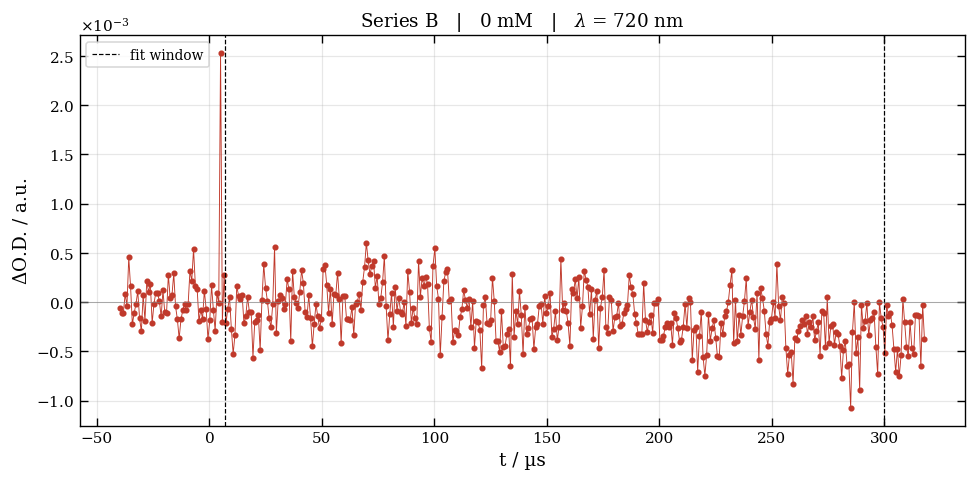

file   : 1E_2M_2Propanol_H2O_N2O_85Gy_B.csv
shape  : 448 time points x 71 wavelengths
t-range: -39.85 to +317.80 µs
wl wish: 720.0 nm -> actual: 720.0 nm


In [48]:
# --- Pick what you want to inspect ------------------------------------------
insp_series     = SELECTED_SERIES     # 'A', 'B', 'C'
insp_value      = 0              # which variable value
insp_wavelength = 720               # wavelength in nm

# take that measurement and the trace at the requested wavelength
d         = data[insp_series][insp_value]
idx       = np.argmin(np.abs(d['wl'] - insp_wavelength))   # nearest available wavelength
wl_actual = d['wl'][idx]
trace     = d['A'][:, idx]
t_scale, t_unit = pick_time_unit(d['t'])

# plot the time trace, with the fit window marked by dashed lines
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(d['t']*t_scale, trace, 'o-', ms=3, lw=0.6, color=ACCENT_COLOR)
ax.axvline(T_FIT_START*t_scale, color='k', ls='--', lw=0.8, label='fit window')
ax.axvline(T_FIT_END  *t_scale, color='k', ls='--', lw=0.8)
ax.axhline(0, color='gray', lw=0.4)
ax.set_xlabel(f't / {t_unit}')
ax.set_ylabel(r'$\Delta$O.D. / a.u.')
ax.ticklabel_format(axis='y', style='sci', scilimits=(0, 0), useMathText=True)
ax.set_title(f'Series {insp_series}   |   '
             rf'{insp_value*LABELS["conc_scale"]:.3g} {LABELS["conc_unit"]}   |   '
             rf'$\lambda$ = {wl_actual:.0f} nm')
ax.grid(alpha=0.3)
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

# short summary of the inspected file
print(f"file   : {FILES[insp_series][insp_value]}")
print(f"shape  : {d['A'].shape[0]} time points x {d['A'].shape[1]} wavelengths")
print(f"t-range: {d['t'].min()*t_scale:+.2f} to {d['t'].max()*t_scale:+.2f} {t_unit}")
print(f"wl wish: {insp_wavelength:.1f} nm -> actual: {wl_actual:.1f} nm")

## Mono-exponential decay fits: $k_\mathrm{obs}$

For every variable value we fit the averaged trace inside $[T_\mathrm{FIT\_START}, T_\mathrm{FIT\_END}]$ with

$$\Delta\mathrm{OD}(t) \;=\; y_\infty + (y_0 - y_\infty)\, \exp\!\bigl[-k_\mathrm{obs}\,(t - T_\mathrm{FIT\_START})\bigr].$$


In [49]:
# Mono-exponential decay model for the fit
def exp_decay(t, y_inf, y0, k):
    return y_inf + (y0 - y_inf) * np.exp(-k * (t - T_FIT_START))


# Noise level from the pre-trigger baseline (used as the fit weight)
def estimate_sigma(t, y, t_baseline_end):
    return float(np.std(y[t < t_baseline_end], ddof=1))


# Fits one trace -> rate k_obs, its error, and the reduced chi-squared
def fit_kobs(t, y, t_start, t_end, t_baseline_end):
    sigma   = estimate_sigma(t, y, t_baseline_end)
    mask    = (t >= t_start) & (t <= t_end)        # points inside the fit window
    tt, yy  = t[mask], y[mask]

    # starting guesses for the three parameters
    n_tail  = max(len(yy) // 10, 5)
    p0_yinf = float(np.median(yy[-n_tail:]))
    p0_y0   = float(yy[0])
    drop    = max(abs(p0_y0 - p0_yinf), 1e-9)
    p0_k    = max(drop / max(abs(p0_y0), 1e-9) / (tt[-1] - tt[0]), 1e5)
    p0      = [p0_yinf, p0_y0, p0_k]

    popt, pcov = curve_fit(exp_decay, tt, yy, p0=p0,
                           sigma=np.full_like(yy, sigma),
                           absolute_sigma=False, maxfev=20000)
    perr = np.sqrt(np.diag(pcov))

    # reduced chi-squared as a goodness-of-fit measure
    y_fit     = exp_decay(tt, *popt)
    residuals = yy - y_fit
    dof       = len(yy) - len(popt)
    chi2_red  = float(np.sum((residuals / sigma) ** 2) / dof)

    return dict(popt=popt, perr=perr,
                k=popt[2], k_err=perr[2],
                chi2_red=chi2_red, sigma=sigma,
                tt=tt, yy=yy, y_fit=y_fit, residuals=residuals)


# Fit every concentration of the selected series and print a summary table
series = SELECTED_SERIES
values = sorted(data[series].keys())
fits   = {}

_d0 = data[series][values[0]]
t_scale, t_unit = pick_time_unit(_d0['t'])
react = LABELS['reactant_text']

# table header
hdr = (f"{f'[{react}]':>16}  "
       f"{'k_obs [s⁻¹]':>24}  "
       f"{f'τ [{t_unit}]':>12}  "
       f"{'χ²_ν':>7}")
print(f"=== Series {series} ===")
print(hdr)
print('-' * len(hdr))

# one row per concentration: k_obs, lifetime τ = 1/k, and chi-squared
for v in values:
    d     = data[series][v]
    trace = extract_trace(d['A'], d['wl'], LAMBDA_MIN, LAMBDA_MAX)
    f     = fit_kobs(d['t'], trace, T_FIT_START, T_FIT_END, T_BASELINE_END)
    fits[v] = f

    v_disp = f"{v*LABELS['conc_scale']:.3g} {LABELS['conc_unit']}"
    tau    = (1.0 / f['k']) * t_scale
    print(f"{v_disp:>16}  "
          f"{f['k']:>9.3e} ± {f['k_err']:.1e}  "
          f"{tau:>12.2f}  "
          f"{f['chi2_red']:>7.2f}")

=== Series B ===
    [FeCl3·6H2O]               k_obs [s⁻¹]        τ [µs]     χ²_ν
-----------------------------------------------------------------
            0 mM  2.817e+04 ± 4.6e+02         35.49   262.59
          0.1 mM  2.310e+04 ± 3.9e+02         43.30   482.17
          0.2 mM  2.137e+04 ± 3.4e+02         46.79   200.23
          0.5 mM  4.239e+04 ± 6.7e+02         23.59   268.87
         0.75 mM  5.449e+04 ± 7.3e+02         18.35   332.48
            1 mM  6.563e+04 ± 7.1e+02         15.24    89.40


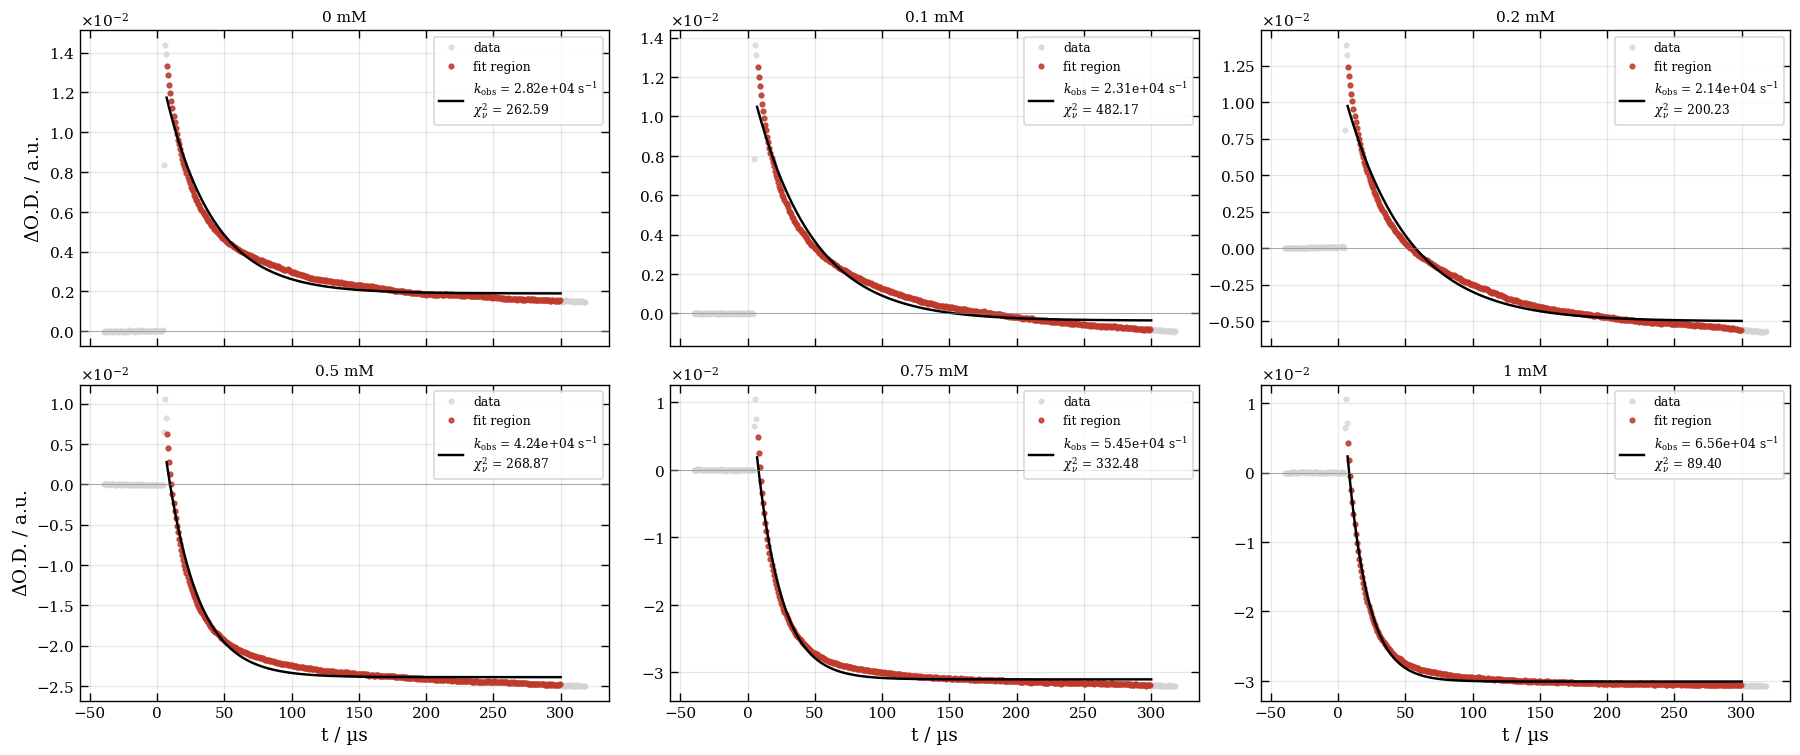

In [50]:
# Grid of all fits, one panel per concentration
fit_values = [v for v in sorted(fits.keys())]
n_cols = 3
n_rows = int(np.ceil(len(fit_values) / n_cols))

# Time unit from the first file (all share the same time axis anyway)
_d0 = data[SELECTED_SERIES][fit_values[0]]
t_scale, t_unit = pick_time_unit(_d0['t'])

fig, axes = plt.subplots(n_rows, n_cols, figsize=(5.5*n_cols, 3.5*n_rows),
                         squeeze=False, sharex=True)

for ax, v in zip(axes.flat, fit_values):
    d     = data[SELECTED_SERIES][v]
    trace = extract_trace(d['A'], d['wl'], LAMBDA_MIN, LAMBDA_MAX)
    f     = fits[v]

    # grey: all points; coloured: the points used in the fit
    ax.plot(d['t']*t_scale, trace, 'o', ms=3, color='lightgray',
            alpha=0.7, label='data')
    ax.plot(f['tt']*t_scale, f['yy'], 'o', ms=3,
            color=ACCENT_COLOR, alpha=0.85, label='fit region')
    # the fitted exponential, with k_obs and chi-squared in the legend
    tp = np.linspace(T_FIT_START, T_FIT_END, 400)
    ax.plot(tp*t_scale, exp_decay(tp, *f['popt']), 'k-', lw=1.6,
            label=(rf"$k_\mathrm{{obs}}$ = {f['k']:.2e} s$^{{-1}}$"
                   "\n"
                   rf"$\chi^2_\nu$ = {f['chi2_red']:.2f}"))

    ax.axhline(0, color='gray', lw=0.4)
    ax.set_title(f"{v*LABELS['conc_scale']:.3g} {LABELS['conc_unit']}", fontsize=10)
    ax.ticklabel_format(axis='y', style='sci', scilimits=(0, 0), useMathText=True)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8, loc='upper right')

# shared axis labels, and hide any empty panels
for ax in axes[-1, :]:
    ax.set_xlabel(f't / {t_unit}')
for ax in axes[:, 0]:
    ax.set_ylabel(r'$\Delta$O.D. / a.u.')
for ax in axes.flat[len(fit_values):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

## Second-order rate constant: $k_\mathrm{obs}$

Under pseudo-first-order conditions,

$$k_\mathrm{obs}\;=\;k_0 \;+\; k_2 \cdot c_\mathrm{reactant}.$$

A weighted linear fit gives the **second-order rate constant $k_2$** as the slope. Points below `MIN_VAR_FOR_LINEAR_FIT` are plotted but excluded from the fit.


In [51]:
# Linear fit k_obs = k_0 + k_2*c -> second-order rate constant k_2
def linear(x, a, b):
    return a + b*x


# collect k_obs vs concentration (skip the zero-concentration point)
fit_values = np.array([v for v in sorted(fits.keys()) if v > 0])
k_obs      = np.array([fits[v]['k']     for v in fit_values])
k_err      = np.array([fits[v]['k_err'] for v in fit_values])

# use only concentrations at or above the threshold for the fit
mask_lin = fit_values >= MIN_VAR_FOR_LINEAR_FIT

# starting guesses for intercept and slope
p0_int   = float(k_obs[mask_lin][0])
p0_slope = float((k_obs[mask_lin][-1] - k_obs[mask_lin][0])
                 / (fit_values[mask_lin][-1] - fit_values[mask_lin][0]))

# weighted linear fit (weights from the k_obs errors)
popt, pcov = curve_fit(linear, fit_values[mask_lin], k_obs[mask_lin],
                       sigma=k_err[mask_lin], absolute_sigma=False,
                       p0=[p0_int, p0_slope])
k_0, k_2          = popt
k_0_err, k_2_err  = np.sqrt(np.diag(pcov))

# Goodness-of-fit diagnostics
res_lin   = k_obs[mask_lin] - linear(fit_values[mask_lin], *popt)
dof_lin   = mask_lin.sum() - len(popt)
chi2_red  = float(np.sum((res_lin / k_err[mask_lin])**2) / dof_lin)

# bundle the results for the plot in the next cell
linfit = dict(values=fit_values, k_obs=k_obs, k_err=k_err, mask=mask_lin,
              k_0=k_0, k_2=k_2, k_0_err=k_0_err, k_2_err=k_2_err,
              chi2_red=chi2_red, residuals=res_lin)

react = LABELS['reactant_text']
print(f"=== Series {SELECTED_SERIES} ===")
print(f"  fitted points : {mask_lin.sum()} of {len(fit_values)}  "
      f"(threshold {MIN_VAR_FOR_LINEAR_FIT*LABELS['conc_scale']:g} "
      f"{LABELS['conc_unit']}, reactant: {react})")
print(f"  k_2  = ({k_2:.3e} ± {k_2_err:.1e}) M⁻¹ s⁻¹")
print(f"  k_0  = ({k_0:.3e} ± {k_0_err:.1e}) s⁻¹")
print(f"  χ²_ν = {chi2_red:.2f}  (dof = {dof_lin})")

=== Series B ===
  fitted points : 4 of 5  (threshold 0.2 mM, reactant: FeCl3·6H2O)
  k_2  = (5.717e+07 ± 3.8e+06) M⁻¹ s⁻¹
  k_0  = (1.053e+04 ± 2.0e+03) s⁻¹
  χ²_ν = 18.93  (dof = 2)


## Final plot: $k_\mathrm{obs}$ vs. reactant concentration


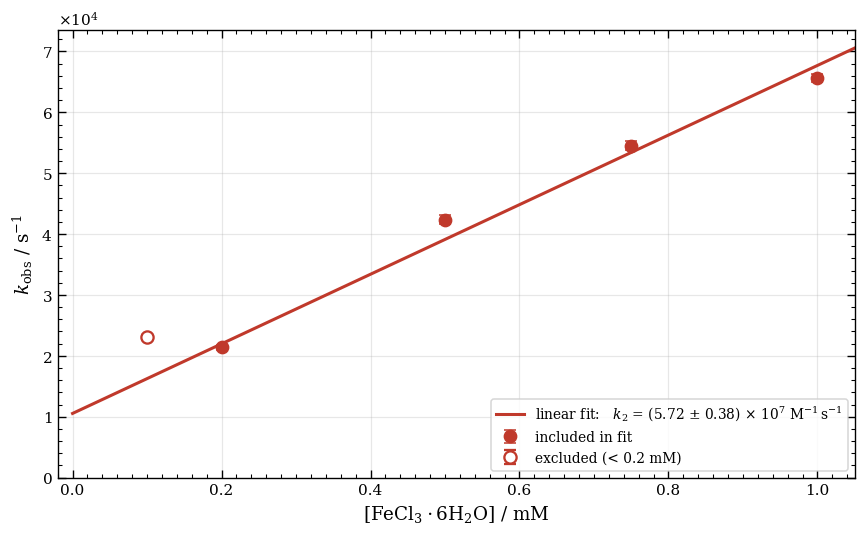

In [52]:
# Final plot: k_obs vs concentration with the weighted linear fit
fig, ax = plt.subplots(figsize=(8, 5))

s   = LABELS['conc_scale']
col = ACCENT_COLOR
lf  = linfit

# Points included in the fit
ax.errorbar(lf['values'][lf['mask']]*s, lf['k_obs'][lf['mask']],
            yerr=lf['k_err'][lf['mask']],
            fmt='o', ms=8, color=col, mfc=col, mec=col, ecolor=col,
            capsize=4, elinewidth=1.0, label='included in fit', zorder=3)

# Excluded points (open symbols)
if (~lf['mask']).any():
    ax.errorbar(lf['values'][~lf['mask']]*s, lf['k_obs'][~lf['mask']],
                yerr=lf['k_err'][~lf['mask']],
                fmt='o', ms=8, mec=col, mfc='white', mew=1.5, ecolor=col,
                capsize=4, elinewidth=1.0,
                label=f"excluded (< {MIN_VAR_FOR_LINEAR_FIT*s:g} {LABELS['conc_unit']})",
                zorder=3)

# Fit line
x_plot = np.linspace(0, lf['values'].max()*1.05, 200)
y_plot = (lf['k_0'] + lf['k_2']*x_plot)

# Formatted slope with matched exponent
exp_   = int(np.floor(np.log10(abs(lf['k_2']))))
mant   = lf['k_2']     / 10**exp_
m_err  = lf['k_2_err'] / 10**exp_
fit_label = (rf"linear fit:   $k_2$ = "
             rf"({mant:.2f} $\pm$ {m_err:.2f})$\,\times\,10^{{{exp_}}}$ "
             rf"$\mathrm{{M^{{-1}}\,s^{{-1}}}}$")
             #"\n"
             #rf"$\chi^2_\nu$ = {lf['chi2_red']:.2f}")

ax.plot(x_plot*s, y_plot, '-', color=col, lw=2, label=fit_label, zorder=2)

ax.set_xlabel(rf"[{LABELS['reactant']}] / {LABELS['conc_unit']}")
ax.set_ylabel(r'$k_\mathrm{obs}$ / s$^{-1}$')
#ax.set_title(r'Reduction of Fe$^{3+}$ by $(\mathrm{CH}_3)_2\dot{\mathrm{C}}\mathrm{OH}$ at pH 10.5')
#ax.set_title(r'Reduction of Fe$^{3+}$ by $\mathrm{e}^-_{\mathrm{aq}}$ at pH 10.5')
ax.set_xlim(-0.02*lf['values'].max()*s, 1.05*lf['values'].max()*s)
ax.set_ylim(bottom=0)
ax.xaxis.set_minor_locator(AutoMinorLocator(10))
ax.yaxis.set_minor_locator(AutoMinorLocator(5))
ax.ticklabel_format(axis='y', style='sci', scilimits=(0, 0), useMathText=True)
ax.grid(alpha=0.3)
ax.legend(fontsize=9, loc='lower right') # upper left

plt.tight_layout()
plt.savefig(f'kobs_vs_conc_series_I.pdf', bbox_inches='tight')
plt.show()

## Determining time of the pulse by hand

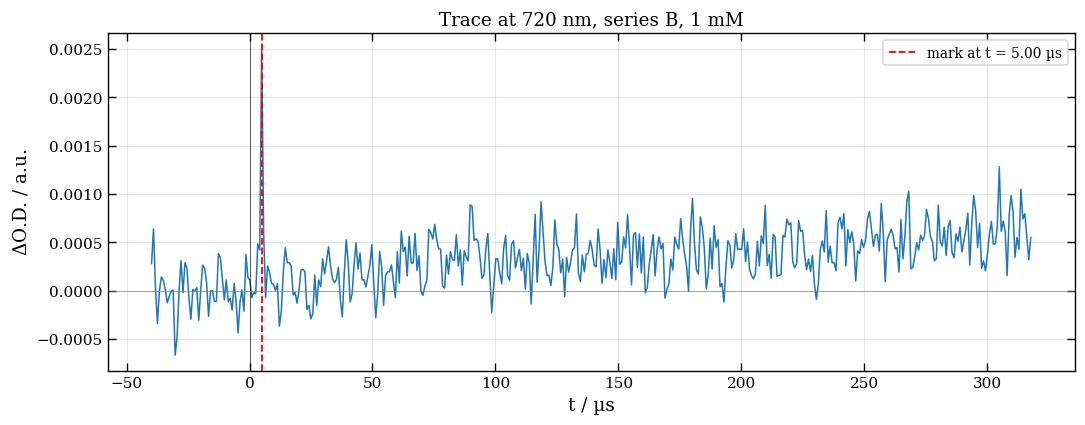

In [53]:
# --- Configuration ---------------------------------------------------------
diag_series = 'B'
diag_value  = 1e-3
diag_wl     = 720
mark_time   = 5e-6    # vertical line at this time [s] - move this to find your spectrum time # -37e-9, 5e-6
# ---------------------------------------------------------------------------

# trace near the chosen wavelength (averaged over a +/- 5 nm window)
d = data[diag_series][diag_value]
t_scale, t_unit = pick_time_unit(d['t'])
trace = extract_trace(d['A'], d['wl'], diag_wl - 5, diag_wl + 5)

# plot the trace with a red dashed marker at mark_time
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(d['t']*t_scale, trace, '-', lw=1)
ax.axvline(0, color='k', lw=0.4)
ax.axhline(0, color='gray', lw=0.4)
ax.axvline(mark_time*t_scale, color='red', lw=1.2, ls='--',
           label=f'mark at t = {mark_time*t_scale:.2f} {t_unit}')
ax.set_xlabel(f't / {t_unit}')
ax.set_ylabel(r'$\Delta$O.D. / a.u.')
ax.set_title(f'Trace at {diag_wl} nm, series {diag_series}, {diag_value*1e3:.2g} mM')
ax.legend(fontsize=9)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

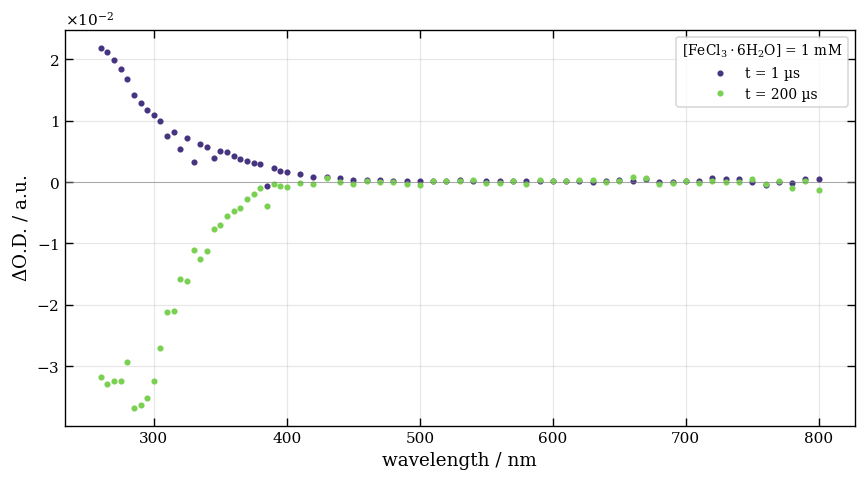

In [54]:
# --- Configuration ---------------------------------------------------------
spec_series = 'B'                   # which series / time base to use
spec_value  = 1e-3                  # single concentration to show
spec_times  = [1e-6, 200e-6]        # times after the pulse to plot (B base: 1e-6, 200e-6)
T_PULSE     = 5e-6                 # time the pulse arrives (4e-6 for B base, -37e-9 for A base)
# ---------------------------------------------------------------------------

# display time unit, and one distinct colour per spectrum
t_scale, t_unit = pick_time_unit(np.array(spec_times))
colors = plt.cm.viridis(np.linspace(0.15, 0.8, len(spec_times)))

d = data[spec_series][spec_value]

# plot the spectrum (absorbance vs. wavelength) at each chosen time
fig, ax = plt.subplots(figsize=(8, 4.5))
for tt, c in zip(spec_times, colors):
    idx        = int(np.argmin(np.abs(d['t'] - (tt + T_PULSE))))   # row closest to that time
    t_after    = d['t'][idx] - T_PULSE                             # time measured from the pulse
    spectrum   = d['A'][idx, :]
    label      = rf't = {t_after*t_scale:.0f} {t_unit}'
    ax.plot(d['wl'], spectrum, 'o', ms=3, color=c, label=label)
    #ax.plot(d['wl'], spectrum, '-', lw=1.3, color=c, label=label)

ax.axhline(0, color='gray', lw=0.4)
ax.set_xlabel('wavelength / nm')
ax.set_ylabel(r'$\Delta$O.D. / a.u.')
ax.ticklabel_format(axis='y', style='sci', scilimits=(0, 0), useMathText=True)
ax.grid(alpha=0.3)
conc_label = (rf'[{LABELS["reactant"]}] = '
              rf'{spec_value*LABELS["conc_scale"]:.3g} {LABELS["conc_unit"]}')
ax.legend(title=conc_label, fontsize=9, title_fontsize=9)
plt.tight_layout()
plt.savefig(f'series_I_spectrum_{spec_series}.pdf', bbox_inches='tight')
plt.show()

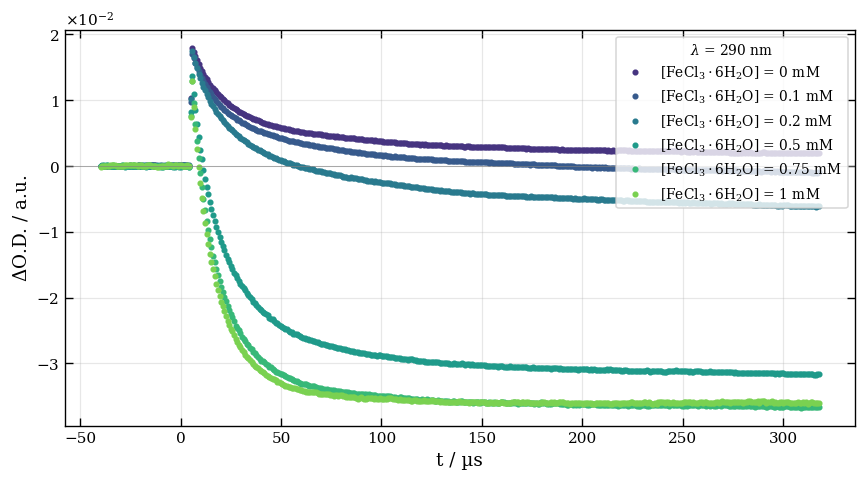

In [57]:
# --- Configuration ---------------------------------------------------------
trace_series      = 'B'              # which series / time base ('A'=20ns, 'C'=200ns, 'B'=20µs)
trace_values      = [0, 1e-4, 2e-4, 5e-4, 7.5e-4, 1e-3]   # concentrations to overlay (mol/L)
trace_wavelength  = 290              # wavelength to plot, in nm
# ---------------------------------------------------------------------------

trace_dlam = 5    # half-width of the wavelength averaging window (nm)
TIMEBASE_LABELS = {'A': '20 ns', 'C': '200 ns', 'B': '20 µs'}

# display time unit (taken from the first concentration; all share the same time axis)
t_scale, t_unit = pick_time_unit(data[trace_series][trace_values[0]]['t'])
# one distinct colour per concentration
colors = plt.cm.viridis(np.linspace(0.15, 0.8, len(trace_values)))

# plot the time trace at the chosen wavelength, one curve per concentration
fig, ax = plt.subplots(figsize=(8, 4.5))
for v, c in zip(trace_values, colors):
    d     = data[trace_series][v]
    trace = extract_trace(d['A'], d['wl'],
                          trace_wavelength - trace_dlam,
                          trace_wavelength + trace_dlam)
    label = (rf'[{LABELS["reactant"]}] = '
             rf'{v*LABELS["conc_scale"]:.3g} {LABELS["conc_unit"]}')
    ax.plot(d['t']*t_scale, trace, 'o', ms=3, color=c, label=label)
    #ax.plot(d['t']*t_scale, trace, '-', lw=1.3, color=c, label=label)

ax.axhline(0, color='gray', lw=0.4)
ax.set_xlabel(f't / {t_unit}')
ax.set_ylabel(r'$\Delta$O.D. / a.u.')
#ax.set_title(f'Corresponding time absorption profile on {TIMEBASE_LABELS[trace_series]} time base')
ax.ticklabel_format(axis='y', style='sci', scilimits=(0, 0), useMathText=True)
ax.grid(alpha=0.3)
ax.legend(title=rf'$\lambda$ = {trace_wavelength:.0f} nm',
          fontsize=9, title_fontsize=9, loc='upper right')
plt.tight_layout()
plt.savefig(f'series_I_traces_{trace_series}_{trace_wavelength}nm.pdf', bbox_inches='tight')
plt.show()